# 34 · 评分、概率、排序与评估边界

公用基础路径：31 → 32 → 33 → 34，再进入搜索、广告或推荐。

**范围：小数组构造机制实验，CPU执行，无真实日志、无正式模型训练或业务收益主张。**

每节先预测 → 只改一个变量 → 运行 → 解释。首次从头执行，后续修改时重跑相关下游格。

## 同一标签下的三种问题

分数决定顺序，sigmoid把实数映射到(0,1)，但映射后的数值不自动具有校准含义。复用项目概率评估。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit
from reclab.probability import evaluate
from sklearn.metrics import ndcg_score
y = np.array([1, 0, 1, 0, 0, 1])
scores = np.array([2., 1., .5, -.5, -1., -2.])
p = expit(scores)
base = evaluate(y, p, bins=3)
print({k: base[k] for k in ['auc', 'logloss', 'brier']})

{'auc': 0.5555555555555556, 'logloss': 0.8047555609137674, 'brier': 0.2803104793171875}


## 只改温度

正温度除法保持顺序，不改变AUC；概率评分却会改变。不要按最终审计集选温度。

0.25 {'auc': 0.5555555555555556, 'logloss': 2.048471115111226, 'brier': 0.3320704642448545}
1.0 {'auc': 0.5555555555555556, 'logloss': 0.8047555609137674, 'brier': 0.2803104793171875}
4.0 {'auc': 0.5555555555555556, 'logloss': 0.685871813125373, 'brier': 0.2462089522244778}


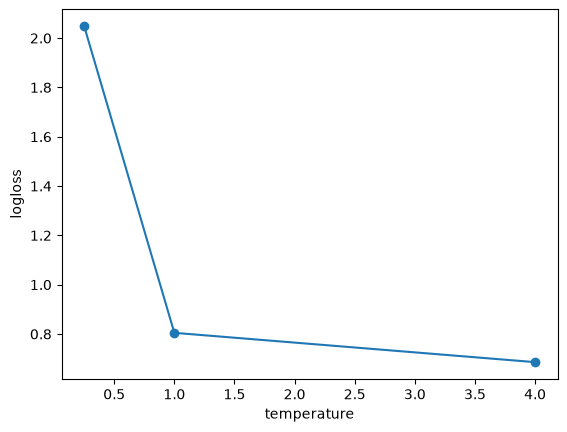

In [2]:
temperatures = [0.25, 1., 4.]
results = [evaluate(y, expit(scores/t), bins=3) for t in temperatures]
assert all(np.isclose(r['auc'], base['auc']) for r in results)
assert len({round(r['logloss'], 6) for r in results}) == 3
for t, r in zip(temperatures, results):
    print(t, {k:r[k] for k in ['auc','logloss','brier']})
plt.plot(temperatures, [r['logloss'] for r in results], 'o-')
plt.xlabel('temperature'); plt.ylabel('logloss'); plt.show()

## 查询内排序与总体分类

AUC跨全部正负样本比较；NDCG按查询衡量前列相关性。这里把六个候选分为两个构造查询。

In [3]:
relevance = y.reshape(2, 3)
query_scores = scores.reshape(2, 3)
ndcg = ndcg_score(relevance, query_scores, k=2)
shifted = query_scores.copy()
shifted[1] += 10  # 只改变第二个查询的整体偏置
assert np.isclose(ndcg_score(relevance, shifted, k=2), ndcg)
assert not np.isclose(evaluate(y, expit(shifted.flatten()))['auc'], base['auc'])
print('NDCG@2:', ndcg, '偏置前后总体AUC:', base['auc'], evaluate(y, expit(shifted.flatten()))['auc'])

NDCG@2: 0.30657359638272924 偏置前后总体AUC: 0.5555555555555556 0.22222222222222224


## 只改候选集合

移除首查询的高分负例会让评估变容易；不能用不同候选池的分数宣称模型进步。

In [4]:
full = ndcg_score(relevance[:1], query_scores[:1], k=2)
keep = [0, 2]
reduced = ndcg_score(relevance[:1, keep], query_scores[:1, keep], k=2)
assert reduced > full
print('完整 / 删除高分负例后的 NDCG@2:', full, reduced)

完整 / 删除高分负例后的 NDCG@2: 0.6131471927654585 1.0


## 解释练习

解释：顺序不变为何logloss改变？查询偏置为何不改变查询内排序却改变总体AUC？离线相关性、点击概率与线上收益分别还缺什么证据？六个构造标签不足以判断真实校准或业务效果。

在下格记录预测、实际结果、差异原因与适用边界；保留失败结果。

In [5]:
reflection = {'预测': '', '结果': '', '解释与边界': ''}
reflection

{'预测': '', '结果': '', '解释与边界': ''}